<a href="https://colab.research.google.com/github/Raffi38321/Projek_ML/blob/main/eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tahap 1: Eksplorasi Data (EDA) — Paket 5C-5
**Mata Kuliah:** Pembelajaran Mesin (INF62325) — Kelas 5C  
**Program Studi:** S1 Informatika, UIN Siber Syekh Nurjati Cirebon  
**Paket Dataset:** 5C-5 — *Students Dropout & Academic Success* (UCI Machine Learning Repository ID: 697)  
**Metode Kelompok:** Klasifikasi (*k-NN* dibandingkan dengan *Naive Bayes*)  
**Anggota Kelompok:**
1. Muhammad Raffi — NIM 2488010046 (Varian 1: Dasar)
2. Pasya urusan bisnis — NIM [...] (Varian 2: Parameter $k$)
3. Ummu dangdut akademi — NIM [...] (Varian 3: Algoritma Pembanding Naive Bayes)

---

### Pernyataan Unit Analisis & Tujuan Pemodelan
* **Unit Analisis:** Satu baris data dalam dataset ini mewakili **satu orang mahasiswa di sebuah institusi pendidikan tinggi di Portugal pada saat pendaftaran**.
* **Tujuan Pemodelan:** Memprediksi status akhir akademik mahasiswa (`Target`) untuk mengidentifikasi risiko putus studi (*Dropout*) dibandingkan kelulusan (*Graduate*) maupun mahasiswa yang masih aktif (*Enrolled*).

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur gaya visualisasi
sns.set_theme(style="whitegrid")

# Langkah 1: Muat berkas data.csv menggunakan pemisah titik koma (;)
df = pd.read_csv('data.csv', sep=';')

# Membersihkan karakter whitespace/tab tersembunyi pada nama kolom (misal: 'Daytime/evening attendance\t')
df.columns = df.columns.str.strip()

print("Ukuran dataset (baris, kolom):", df.shape)
display(df.head(5))

Ukuran dataset (baris, kolom): (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [13]:
# Memeriksa tipe data setiap kolom dan jumlah non-null
df.info()

# Ringkasan statistik kolom numerik dan target kategori
display(df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])
display(df.describe(include='object'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

,count,mean,std,min,50%,max
Marital status,4424.0,1.178571,0.605747,1.00,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,17.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9238.000000,9991.000000
Daytime/evening attendance,4424.0,0.890823,0.311897,0.00,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,133.100000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,19.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,19.000000,44.000000


,Target
count,4424
unique,3
top,Graduate
freq,2209


### Temuan Langkah 1 & 2 (Struktur & Tipe Data)
1. **Ukuran Data:** Berkas `data.csv` terbaca utuh sebesar **4.424 baris × 37 kolom** (36 fitur + 1 variabel target `Target`), sesuai dengan spesifikasi Paket 5C-5.
2. **Perbaikan Nama Kolom:** Ditemukan karakter tab (`\t`) di akhir nama kolom `Daytime/evening attendance\t` yang telah dibersihkan dengan `.str.strip()`.
3. **Ketidaksesuaian Tipe & Arti Kolom (Temuan Utama):**
   * Banyak kolom bertipe `int64` yang secara makna bukan besaran numerik kontinu, melainkan **kode kategori nominal** dari dokumentasi resmi UCI, yaitu: `Marital status` (6 kode), `Application mode` (18 kode), `Course` (17 kode), `Previous qualification` (17 kode), `Nacionality` (21 kode), `Mother's qualification` (29 kode), `Father's qualification` (34 kode), `Mother's occupation` (32 kode), dan `Father's occupation` (46 kode).
   * Pada tahap praproses pemodelan (*Tahap 2*), kolom-kolom kode kategori ini wajib di-*encoding* (misalnya *One-Hot Encoding*) agar algoritma *k-NN* tidak keliru menganggap kode program studi `9991` lebih besar daripada kode `33`.

In [14]:

hilang = df.isna().sum()
print("1. Jumlah nilai hilang (NaN):", hilang.sum())

sem1_zero = (df['Curricular units 1st sem (grade)'] == 0).sum()
sem2_zero = (df['Curricular units 2nd sem (grade)'] == 0).sum()
print(f"2. Data hilang tersamar -> Sem 1 grade == 0: {sem1_zero} baris ({sem1_zero/len(df)*100:.2f}%)")
print(f"   Data hilang tersamar -> Sem 2 grade == 0: {sem2_zero} baris ({sem2_zero/len(df)*100:.2f}%)")

print("3. Jumlah baris duplikat identik:", df.duplicated().sum())

n = df.nunique()
print("4. Kolom konstan (nunique <= 1):", list(n[n <= 1].index))
print("5. Kandidat identifier (nunique > 90% baris):", list(n[n > 0.9 * len(df)].index))

Q1 = df['Age at enrollment'].quantile(0.25)
Q3 = df['Age at enrollment'].quantile(0.75)
IQR = Q3 - Q1
outliers_age = df[(df['Age at enrollment'] < Q1 - 1.5*IQR) | (df['Age at enrollment'] > Q3 + 1.5*IQR)]
print(f"6. Usia pendaftaran -> Min: {df['Age at enrollment'].min()}, Max: {df['Age at enrollment'].max()}, Pencilan IQR (>34 thn): {len(outliers_age)} baris")

print("7. Nilai unik kolom Target:", df['Target'].unique())

1. Jumlah nilai hilang (NaN): 0
2. Data hilang tersamar -> Sem 1 grade == 0: 718 baris (16.23%)
   Data hilang tersamar -> Sem 2 grade == 0: 870 baris (19.67%)
3. Jumlah baris duplikat identik: 0
4. Kolom konstan (nunique <= 1): []
5. Kandidat identifier (nunique > 90% baris): []
6. Usia pendaftaran -> Min: 17, Max: 70, Pencilan IQR (>34 thn): 441 baris
7. Nilai unik kolom Target: ['Dropout' 'Graduate' 'Enrolled']


### Temuan Langkah 3 (Pemeriksaan Mutu Data)
* **Nilai Hilang, Duplikat, Kolom Konstan & Identifier:** Tidak ditemukan nilai `NaN` (`0`), tidak ada baris duplikat (`0`), tidak ada kolom konstan (`[]`), dan tidak ada kolom *identifier* unik per baris (`[]`).
* **Data Hilang Tersamar (4 poin temuan):** Terdapat **718 baris (16,23%)** dengan `Curricular units 1st sem (grade) == 0` dan **870 baris (19,67%)** dengan `Curricular units 2nd sem (grade) == 0`. Berdasarkan kamus data UCI, nilai `0` tersebut menandakan mahasiswa tidak mengambil/tidak mengikuti evaluasi mata kuliah pada semester berjalan (bukan nilai ujian nol murni). Data ini **dipertahankan** karena merupakan sinyal kuat bagi mahasiswa yang berhenti kuliah (*Dropout*).
* **Pencilan Nyata (`Age at enrollment`):** Ditemukan 441 baris dengan usia di atas 34 tahun (rentang 17–70 tahun). Nilai ini adalah **pencilan nyata** (mahasiswa dewasa/kuliah malam), bukan kesalahan input, sehingga **tidak dibuang** agar model tetap merepresentasikan seluruh populasi mahasiswa.

In [15]:
# 4. Sebaran kelas Target & Garis Dasar (Baseline)
vc = df['Target'].value_counts()
vcp = (df['Target'].value_counts(normalize=True) * 100).round(2)
ringkasan_target = pd.DataFrame({'Jumlah': vc, 'Persentase (%)': vcp})
display(ringkasan_target)

baseline = df['Target'].value_counts(normalize=True).max()
print(f"Garis dasar (baseline) kelas mayoritas: {baseline:.2%}")

# 5a. Pemeriksaan hubungan/korelasi fitur numerik terhadap Target (potensi temporal leakage)
df_cek = df.copy()
df_cek['Target_kode'] = df_cek['Target'].map({'Dropout': 0, 'Enrolled': 1, 'Graduate': 2})
kor_target = df_cek.select_dtypes('number').corr()['Target_kode'].drop('Target_kode').sort_values()

print("\n5 Fitur dengan Korelasi Negatif Terkuat terhadap Target:")
print(kor_target.head(5).round(3))
print("\n5 Fitur dengan Korelasi Positif Terkuat terhadap Target:")
print(kor_target.tail(5).round(3))

# 5b. Pemeriksaan multikolinearitas antarfitur (korelasi > 0.80)
num_cols = df.select_dtypes('number').columns
corr_matrix = df[num_cols].corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr = [(col, row, round(upper.loc[row, col], 3))
             for col in upper.columns for row in upper.index if upper.loc[row, col] > 0.80]
print("\nPasangan fitur dengan korelasi tinggi (> 0.80):")
for item in high_corr:
    print(f"  {item[0]} <-> {item[1]} : r = {item[2]}")

,Jumlah,Persentase (%)
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


Garis dasar (baseline) kelas mayoritas: 49.93%

5 Fitur dengan Korelasi Negatif Terkuat terhadap Target:
Age at enrollment                                -0.243
Debtor                                           -0.241
Gender                                           -0.229
Application mode                                 -0.222
Curricular units 2nd sem (without evaluations)   -0.094
Name: Target_kode, dtype: float64

5 Fitur dengan Korelasi Positif Terkuat terhadap Target:
Tuition fees up to date                0.410
Curricular units 1st sem (grade)       0.485
Curricular units 1st sem (approved)    0.529
Curricular units 2nd sem (grade)       0.567
Curricular units 2nd sem (approved)    0.624
Name: Target_kode, dtype: float64

Pasangan fitur dengan korelasi tinggi (> 0.80):
  Father's occupation <-> Mother's occupation : r = 0.91
  Curricular units 2nd sem (credited) <-> Curricular units 1st sem (credited) : r = 0.945
  Curricular units 2nd sem (enrolled) <-> Curricular units 1st sem (

### Temuan Langkah 4 & 5 (Target, Kebocoran Data & Korelasi Antarfitur)
1. **Ketidakseimbangan Kelas & Garis Dasar:**
   * Sebaran target terdiri atas `Graduate` **2.209 (49,93%)**, `Dropout` **1.421 (32,12%)**, dan `Enrolled` **794 (17,95%)**.
   * **Garis dasar (*baseline*) akurasi kelas mayoritas adalah 49,93%**. Model klasifikasi pada Tahap 2 harus melampaui angka ini serta dievaluasi menggunakan *F1-Score* dan *Confusion Matrix*, bukan akurasi semata.
   * **Keputusan Kelas:** Kami mempertahankan **ketiga kelas (`Dropout`, `Enrolled`, `Graduate`)** agar mencakup seluruh kondisi mahasiswa, dengan catatan bahwa kelas minoritas `Enrolled` (17,95%) memiliki batas yang lebih tumpang tindih dengan `Graduate`.
2. **Analisis Kebocoran Data Waktu (*Temporal Data Leakage*):**
   * Fitur akademik semester 1 dan 2 (`Curricular units 2nd sem (approved)` dengan $r = 0,624$ dan `Curricular units 2nd sem (grade)` dengan $r = 0,567$) memiliki korelasi paling kuat terhadap kelulusan.
   * Jika sistem ditujukan untuk **deteksi dini sebelum perkuliahan dimulai**, fitur semester 1–2 merupakan kebocoran waktu (*temporal leakage*) dan tidak boleh dipakai. Namun, karena ruang lingkup proyek ini adalah **evaluasi risiko putus studi setelah mahasiswa menempuh tahun pertama**, fitur semester 1–2 **sah digunakan** sebagai prediktor utama (dan dapat dibandingkan skenarionya tanpa fitur semester pada diskusi laporan).
3. **Multikolinearitas Antarfitur (Implikasi untuk Naive Bayes):**
   * Ditemukan 5 pasang fitur dengan korelasi sangat tinggi ($r > 0,80$), terutama antara performa semester 1 dan semester 2 (misalnya `1st sem enrolled` vs `2nd sem enrolled` dengan $r = 0,943$).
   * Hal ini melanggar asumsi independensi fitur pada **Naive Bayes (Varian 3)**, sehingga menjadi landasan teoretis yang kuat apabila performa Naive Bayes berada di bawah **k-NN (Varian 1 & 2)**.

/tmp/ipykernel_884/400267674.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Target', order=['Graduate', 'Dropout', 'Enrolled'], palette='Set2', ax=axes[0, 0])
/tmp/ipykernel_884/400267674.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Target', y='Curricular units 2nd sem (approved)', order=['Graduate', 'Dropout', 'Enrolled'], palette='Set2', ax=axes[0, 1])
/tmp/ipykernel_884/400267674.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Target', y='Curricular units 2nd sem (grade)', order=['Gra

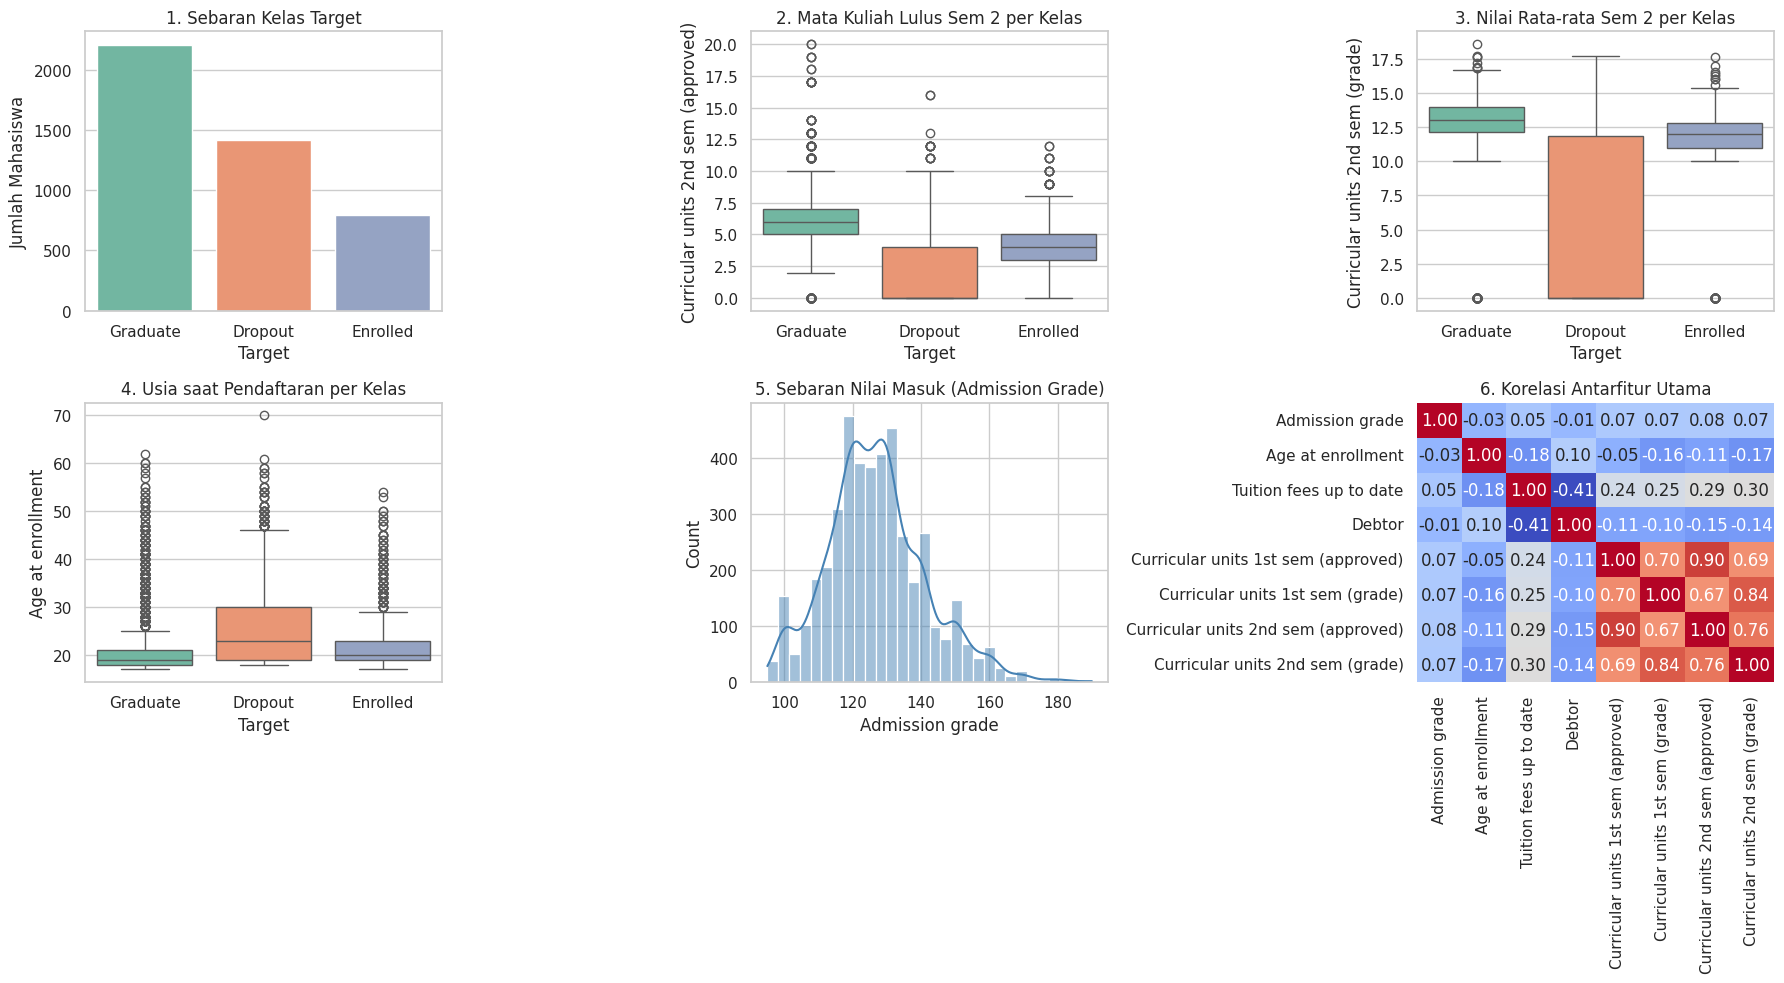

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Grafik 1: Ketidakseimbangan kelas target
sns.countplot(data=df, x='Target', order=['Graduate', 'Dropout', 'Enrolled'], palette='Set2', ax=axes[0, 0])
axes[0, 0].set_title('1. Sebaran Kelas Target')
axes[0, 0].set_ylabel('Jumlah Mahasiswa')

# Grafik 2: Pemisahan kelas oleh Mata Kuliah Lulus Sem 2
sns.boxplot(data=df, x='Target', y='Curricular units 2nd sem (approved)', order=['Graduate', 'Dropout', 'Enrolled'], palette='Set2', ax=axes[0, 1])
axes[0, 1].set_title('2. Mata Kuliah Lulus Sem 2 per Kelas')

# Grafik 3: Pemisahan kelas oleh Nilai Rata-rata Sem 2
sns.boxplot(data=df, x='Target', y='Curricular units 2nd sem (grade)', order=['Graduate', 'Dropout', 'Enrolled'], palette='Set2', ax=axes[0, 2])
axes[0, 2].set_title('3. Nilai Rata-rata Sem 2 per Kelas')

# Grafik 4: Pemisahan kelas oleh Usia Pendaftaran
sns.boxplot(data=df, x='Target', y='Age at enrollment', order=['Graduate', 'Dropout', 'Enrolled'], palette='Set2', ax=axes[1, 0])
axes[1, 0].set_title('4. Usia saat Pendaftaran per Kelas')

# Grafik 5: Histogram Sebaran Admission Grade
sns.histplot(data=df, x='Admission grade', bins=30, kde=True, color='steelblue', ax=axes[1, 1])
axes[1, 1].set_title('5. Sebaran Nilai Masuk (Admission Grade)')

# Grafik 6: Peta Panas Korelasi Fitur Akademik & Ekonomi Utama
fitur_utama = [
    'Admission grade', 'Age at enrollment', 'Tuition fees up to date', 'Debtor',
    'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)',
    'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)'
]
sns.heatmap(df[fitur_utama].corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1, 2], cbar=False)
axes[1, 2].set_title('6. Korelasi Antarfitur Utama')

plt.tight_layout()
plt.show()

### Penafsiran Visualisasi (Langkah 6)
1. **Grafik 1 (Sebaran Kelas Target):** Kelas `Graduate` mendominasi hampir separuh dataset (49,93%), diikuti `Dropout` (32,12%) dan `Enrolled` (17,95%), sehingga dataset tergolong tidak seimbang moderat.
2. **Grafik 2 (Mata Kuliah Lulus Sem 2 per Kelas):** Mahasiswa `Graduate` memiliki median kelulusan 6 mata kuliah per semester, sedangkan `Dropout` memiliki median mendekati 0—menunjukkan fitur ini memisahkan kelas secara tajam.
3. **Grafik 3 (Nilai Rata-rata Sem 2 per Kelas):** Banyak mahasiswa `Dropout` menumpuk pada nilai 0 (tidak mengikuti evaluasi), sementara `Graduate` terkonsentrasi di rentang nilai 12–14.
4. **Grafik 4 (Usia saat Pendaftaran per Kelas):** Mahasiswa yang mengalami `Dropout` cenderung mendaftar pada usia yang lebih tua (median 23 tahun, kuartil atas 30 tahun) dibandingkan mahasiswa `Graduate` (median 20 tahun).
5. **Grafik 5 (Sebaran Nilai Masuk):** `Admission grade` berdistribusi mendekati simetris di sekitar nilai 126 dengan rentang ketat antara 95 hingga 190 tanpa nilai mustahil.
6. **Grafik 6 (Korelasi Antarfitur Utama):** Terlihat blok korelasi kuat ($r = 0,84$ hingga $0,90$) antara jumlah mata kuliah lulus dan nilai rata-rata semester 1 dengan semester 2.

### Tabel Keputusan Praproses (Langkah 7)

| Kolom / Baris | Temuan | Keputusan | Alasan | Baris Terpengaruh |
| :--- | :--- | :--- | :--- | :--- |
| `Daytime/evening attendance\t` | Terdapat karakter tab (`\t`) di akhir nama kolom | Dibersihkan dengan `.str.strip()` | Mencegah *KeyError* saat pemanggilan kolom di tahap pemodelan | 4.424 baris (1 kolom) |
| `Curricular units 1st & 2nd sem (grade)` | Bernilai `0.0` pada 718 baris (Sem 1) dan 870 baris (Sem 2) | **Dipertahankan** apa adanya | Nilai `0.0` berarti mahasiswa tidak mengikuti evaluasi semester tersebut, yang menjadi indikator kuat status `Dropout` | 0 baris dibuang |
| `Age at enrollment` | Terdapat 441 baris di atas batas atas IQR (> 34 tahun, maks 70 tahun) | **Dipertahankan** apa adanya | Merupakan usia nyata mahasiswa kelas karyawan/dewasa, bukan kesalahan pencatatan | 0 baris dibuang |
| Kolom kode kategori (`Course`, `Application mode`, dll.) | Bertipe `int64` tetapi merupakan kode kategori nominal | Dicatat untuk **One-Hot Encoding** di `02_praproses.ipynb` | Mencegah algoritma *k-NN* menghitung jarak numerik palsu antar kode kategori | 9 kolom fitur |
| Seluruh fitur numerik | Rentang skala sangat timpang (misal `Admission grade` 95–190 vs biner 0–1) | Dicatat untuk **StandardScaler** setelah `train_test_split` | Wajib untuk *k-NN* berbasis jarak Euclidean, dan dilakukan setelah split agar bebas kebocoran data | Seluruh fitur |

In [19]:
# Menyimpan dataset yang telah distandardisasi nama kolomnya dan diverifikasi mutunya
df_bersih = df.copy()
df_bersih.to_csv('data_bersih.csv', index=False)

print("Ukuran awal  :", df.shape)
print("Ukuran bersih:", df_bersih.shape)
print("Berkas 'data_bersih.csv' berhasil disimpan.")

Ukuran awal  : (4424, 37)
Ukuran bersih: (4424, 37)
Berkas 'data_bersih.csv' berhasil disimpan.
